# Compare offline replays of a recorded session

Replays of the same recorded session (`source: offline`, e.g. NRR_RW011 files 12–21) with
different stim orders: WASABI's D-optimal choices against the order the experiment was
recorded in (`Sequential`). Both draw from the same recorded trials and the same control
fit; only the order differs, so this shows how much faster WASABI's ordering pins down B.

Leave `RUNS = None` for the newest history of each strategy in `results/offline`, or list
files to compare.

In [108]:
RUNS = None   # or {"D-optimal": "results/offline/history_doptimal_....npz", "Sequential": "..."}
STRATEGIES = {"D-optimal": "doptimal", "Sequential": "sequential"}   # label: history name, for RUNS = None
FIRST_N = 50      # compare which recorded stims were used in the first FIRST_N trials
GROUP_SIZE = 4    # channels per stim group, as stim.group_size in the config
# Final B the error-to-final panel compares against: a run label (its final estimate is the
# reference for every run) or None (each run against its own final estimate). Sequential by
# default: D-optimal's replay ends on long runs of the last stims left, where B can diverge.
REFERENCE = "Sequential"

In [109]:
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import ListedColormap
from matplotlib.ticker import MaxNLocator

ROOT = Path.cwd().parent if Path.cwd().name == "scripts" else Path.cwd()

if RUNS is None:
    RUNS = {}
    for label, name in STRATEGIES.items():
        files = sorted((ROOT / "results" / "offline").glob(f"history_{name}_*.npz"), key=lambda p: p.stat().st_mtime)
        if not files:
            raise FileNotFoundError(f"no results/offline/history_{name}_*.npz")
        RUNS[label] = files[-1]

# Categorical slots of the validated default palette, fixed per strategy
COLORS = dict(zip(RUNS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]))
INK, MUTED, GRID = "#1f1f1e", "#6b6a63", "#e4e3df"
plt.rcParams.update({
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": False, "grid.color": GRID, "grid.linewidth": 0.6, "axes.spines.top": False,
    "axes.spines.right": False, "axes.titlesize": 11, "axes.titlelocation": "left",
    "legend.frameon": False, "lines.linewidth": 1.6,
})


def channel_label(pattern):
    c = np.flatnonzero(pattern) + 1
    runs = np.split(c, np.flatnonzero(np.diff(c) != 1) + 1)
    return ", ".join(f"{r[0]}-{r[-1]}" for r in runs)


H = {name: dict(np.load(ROOT / path)) for name, path in RUNS.items()}
for name, path in RUNS.items():
    print(f"{name:11s} {Path(path).name}: {len(H[name]['choice'])} trials")

# Every run should replay the same recorded stims, with the same control fit
ref_name, ref = next(iter(H)), next(iter(H.values()))
labels = [channel_label(p) for p in ref["candidates"]]
for name, h in H.items():
    assert np.array_equal(h["candidates"], ref["candidates"]), f"{name} replays different stims"
    a, b = h["control_fit_losses"], ref["control_fit_losses"]
    rel = np.max(np.abs(a - b) / np.abs(b)) if a.shape == b.shape else np.inf
    print(f"{name:11s} control fit vs {ref_name}: max relative difference {rel:.1e} ({'same' if rel < 1e-4 else 'DIFFERENT'})")
print("stims:", ", ".join(labels))

D-optimal   history_doptimal_20261104_091541.npz: 263 trials
Sequential  history_sequential_20261104_085840.npz: 263 trials
D-optimal   control fit vs D-optimal: max relative difference 0.0e+00 (same)
Sequential  control fit vs D-optimal: max relative difference 6.0e-06 (same)
stims: 1-8, 5-12, 9-16, 13-20, 17-24, 21-28, 25-32, 29-36, 33-40, 37-44


## Summary

`trials to X%` is how many trials each run needed to get X% of the way from the prior's
log det to the lowest log det reached by any run. Fitting / acquisition medians leave out
the first trial / first stim, which include JIT compilation.

In [110]:
target = min(h["logdet"].min() for h in H.values())
print(f"{'':11s} {'trials':>6s}  {'logdet@25':>9s} {'@50':>7s} {'@100':>7s} {'end':>7s}   "
      f"{'to 50%':>6s} {'to 75%':>6s} {'to 90%':>6s}   {'NLL start':>9s} {'end':>7s}  {'fitting':>7s} {'acq.':>6s}")
for name, h in H.items():
    ld, n = h["logdet"], len(h["choice"])
    start = ld[0]
    reach = []
    for frac in (0.5, 0.75, 0.9):
        hit = np.flatnonzero(ld <= start + frac * (target - start))
        reach.append(f"{hit[0] + 1:6d}" if len(hit) else f"{'-':>6s}")
    at = [f"{ld[t]:7.1f}" if t < n else f"{'-':>7s}" for t in (24, 49, 99)]
    print(f"{name:11s} {n:6d}  {at[0]:>9s} {at[1]} {at[2]} {ld[-1]:7.1f}   {' '.join(reach)}   "
          f"{h['refit_loss'][0]:9.3f} {h['refit_loss'][-1]:7.3f}  {np.median(h['fitting_s'][1:]):6.2f}s "
          f"{np.median(h['acquisition_s'][2:]):5.3f}s")

            trials  logdet@25     @50    @100     end   to 50% to 75% to 90%   NLL start     end  fitting   acq.
D-optimal      263     -223.1  -258.4  -294.9  -333.5       10     45    121      58.803  66.522    0.37s 0.006s
Sequential     263     -108.6  -143.1  -179.6  -317.9      110    190    242      58.487  64.604    0.36s 0.000s


## Uncertainty in B, reconstruction loss and distance to the final B

Lower log det = more certain about B (certainty, not correctness). Both runs end on the same
recorded trials, so the gap between the lines is the gain from the order WASABI chose.

There is no ground truth offline, so the third panel measures how far each trial's estimate is
from a reference final estimate: the relative error of the stim effect $B u$ over the recorded
stims, as the simulation's error against the ground truth,
$\|B_t u_t - B'_\mathrm{ref} u_\mathrm{ref}\| / \|B'_\mathrm{ref} u_\mathrm{ref}\|$, with $u = u(s; b)$
of each estimate. The refit rotates the latents, so the reference is first expressed in trial
$t$'s latent basis, $B'_\mathrm{ref} = C_t^\top C_\mathrm{ref} B_\mathrm{ref}$ (C has orthonormal
columns, so $C_t x_t = C_\mathrm{ref} x_\mathrm{ref}$; this is `basis_change` in the code). The reference is the final estimate of run `REFERENCE` (or, with
`REFERENCE = None`, each run's own final estimate, which makes every curve reach 0 at its last
trial by construction). Both runs end on the same recorded trials, so their final estimates
should agree; the printed gap between them checks that. It needs histories that record the
fitted B per trial (`B_trial`).

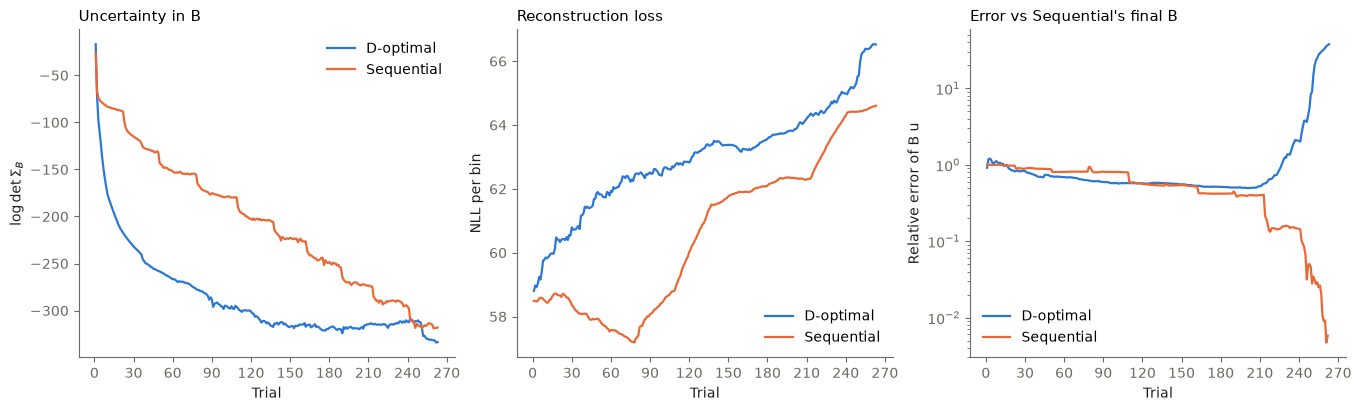

final stim effect B u, D-optimal vs Sequential: relative difference 37.753


In [111]:
BETA_STIM = 5.0  # softplus sharpness of the stim input, LinearDynamics.beta_stim


def stim_input(patterns, b, beta=BETA_STIM):
    """u = softplus(s + b) - softplus(b), the model's stim input with V = I."""
    sp = lambda x: np.logaddexp(0.0, beta * x) / beta
    return sp(patterns + b) - sp(b)


def effect_error(h, ref):
    """Per trial of `h`, the relative error of B u over the recorded stims against the final
    estimate of run `ref`, the reference expressed in each trial's latent basis."""
    B_ref, C_ref = ref["B_trial"][-1], ref["C_trial"][-1]
    u_ref = stim_input(ref["candidates"], ref["b_trial"][-1])  # (n_stims, S)
    err = []
    for B, C, b in zip(h["B_trial"], h["C_trial"], h["b_trial"]):
        target = (C.T @ C_ref @ B_ref) @ u_ref.T  # (K, n_stims) in this trial's basis
        err.append(np.linalg.norm(B @ stim_input(h["candidates"], b).T - target) / np.linalg.norm(target))
    return np.array(err)


has_B = [name for name, h in H.items() if "B_trial" in h]
if REFERENCE is not None and REFERENCE not in has_B:
    raise ValueError(f"REFERENCE {REFERENCE!r} is not a run with per-trial B: {has_B}")
fig, axes = plt.subplots(1, 3 if has_B else 2, figsize=(13.5 if has_B else 13, 4), constrained_layout=True)
for name, h in H.items():
    trials = np.arange(1, len(h["choice"]) + 1)
    axes[0].plot(trials, h["logdet"], color=COLORS[name], label=name)
    axes[1].plot(trials, h["refit_loss"], color=COLORS[name], label=name)
    if name in has_B:
        err = effect_error(h, H[name if REFERENCE is None else REFERENCE])
        # Against its own final estimate a run's last trial is 0 by construction
        last = len(trials) - 1 if name == REFERENCE or REFERENCE is None else len(trials)
        axes[2].plot(trials[:last], err[:last], color=COLORS[name], label=name)
axes[0].set(xlabel="Trial", ylabel=r"$\log\det \Sigma_B$", title="Uncertainty in B")
axes[1].set(xlabel="Trial", ylabel="NLL per bin", title="Reconstruction loss")
axes[0].legend(loc="upper right")
axes[1].legend(loc="lower right")
if has_B:
    axes[2].set_yscale("log")
    reference = "own final B" if REFERENCE is None else f"{REFERENCE}'s final B"
    axes[2].set(xlabel="Trial", ylabel="Relative error of B u", title=f"Error vs {reference}")
    axes[2].legend(loc="lower left")
for ax in axes:
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
plt.show()

missing = [name for name in H if name not in has_B]
if missing:
    print(f"no per-trial B in {', '.join(missing)}: rerun with the current wasabi_online.py")
for a, b in zip(has_B, has_B[1:]):
    gap = effect_error({k: H[a][k][-1:] for k in ("B_trial", "C_trial", "b_trial")} | {"candidates": H[a]["candidates"]}, H[b])[0]
    print(f"final stim effect B u, {a} vs {b}: relative difference {gap:.3f}")

## Which recorded stims were used

The stim each run took on every trial, and how many trials of each stim it had used by
trial `FIRST_N`. Sequential uses up one stim before moving to the next; WASABI spreads its
early trials across stims.

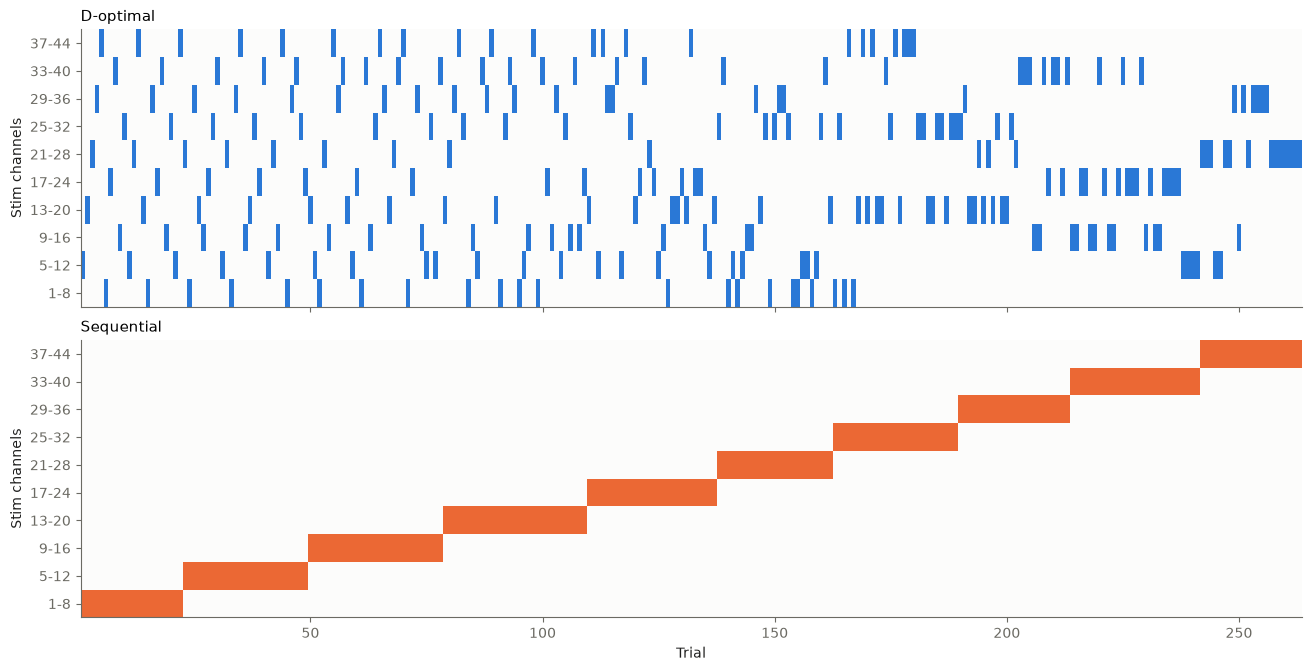

In [117]:
names = list(H)
num_cond = len(labels)
fig, axes = plt.subplots(len(names), 1, figsize=(13, 1.0 + 0.28 * num_cond * len(names)), sharex=True,
                         constrained_layout=True)
for ax, name in zip(np.atleast_1d(axes), names):
    choice = H[name]["choice"]
    grid = np.zeros((num_cond, len(choice)))
    grid[choice, np.arange(len(choice))] = 1
    ax.imshow(grid, aspect="auto", interpolation="nearest", origin="lower",
              cmap=ListedColormap(["#fcfcfb", COLORS[name]]), extent=(0.5, len(choice) + 0.5, -0.5, num_cond - 0.5))
    ax.set(yticks=np.arange(num_cond), yticklabels=labels, ylabel="Stim channels", title=f"{name}")
np.atleast_1d(axes)[-1].set_xlabel("Trial")
plt.show()

## Time per step

Fitting (filter + refit) and acquisition (choosing the next stim), on separate axes. The
first trial / first stim include JIT compilation and are left out. Spikes in D-optimal's
acquisition time come from recompiling when a recorded stim runs out of trials and the
candidate set shrinks.

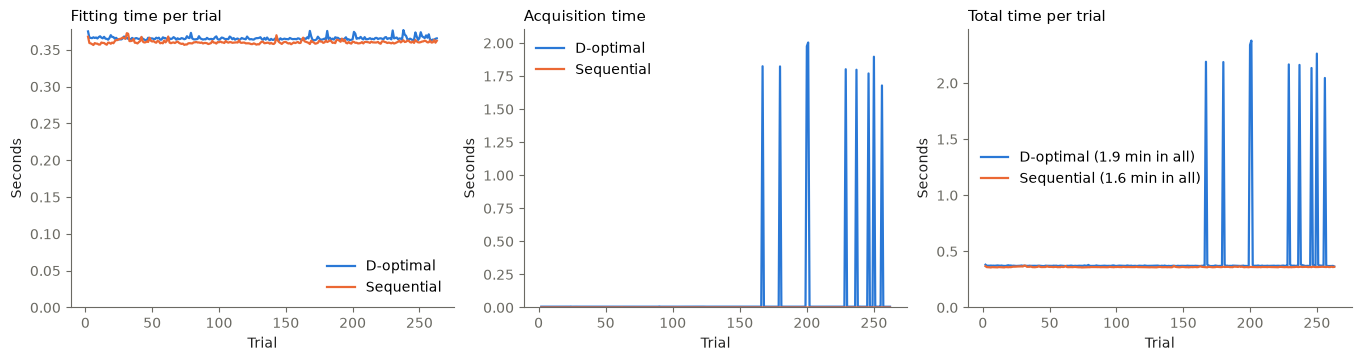

In [118]:
def total_time(h):
    """Load + fitting + the acquisition for the next stim, per trial: roughly the time between
    trials. A replay that runs out of trials makes no decision after its last one; missing
    stages (e.g. load_s in older histories) count as 0."""
    n = len(h["choice"])
    acquisition = np.full(n, np.nan)
    after = h["acquisition_s"][1:n + 1]  # acquisition_s[t] is the decision after trial t
    acquisition[:len(after)] = after
    return np.nansum(np.stack([h["load_s"][:n], h["fitting_s"][:n], acquisition]), axis=0)


fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.5), constrained_layout=True)
for name, h in H.items():
    trials = np.arange(1, len(h["choice"]) + 1)
    axes[0].plot(trials[1:], h["fitting_s"][1:], color=COLORS[name], label=name)
    # A replay that runs out of trials makes no stim decision after its last trial
    acquisition = h["acquisition_s"][2:]
    axes[1].plot(trials[1:1 + len(acquisition)], acquisition, color=COLORS[name], label=name)
    total = total_time(h)
    # Trial 1 includes JIT compilation, so the session total leaves it out like the plot
    axes[2].plot(trials[1:], total[1:], color=COLORS[name], label=f"{name} ({total[1:].sum() / 60:.1f} min in all)")
axes[0].set(xlabel="Trial", ylabel="Seconds", title="Fitting time per trial")
axes[1].set(xlabel="Trial", ylabel="Seconds", title="Acquisition time")
axes[2].set(xlabel="Trial", ylabel="Seconds", title="Total time per trial")
for ax in axes:
    ax.set_ylim(bottom=0)
axes[0].legend(loc="lower right")
axes[1].legend(loc="upper left")
axes[2].legend(loc="center left")
plt.show()

### D-optimal: where the time goes on each trial

Loading the trial, fitting (joint filter + refit) and acquisition (scoring the candidates for
the next stim) for one run, on one log axis since they differ by orders of magnitude. The time
between trials is roughly their sum. Trial 1's fitting and the first two stim decisions include
JIT compilation and are left out, as above.

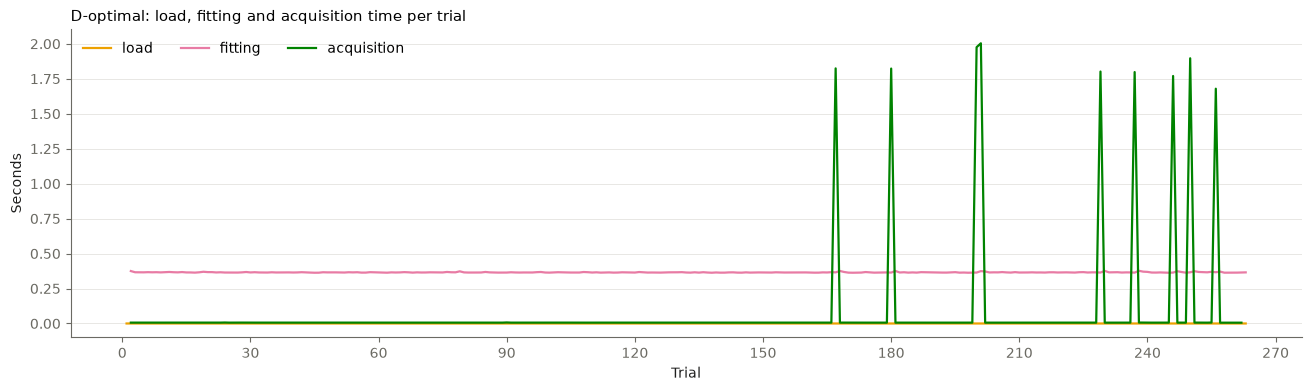

In [114]:
TIMING_RUN = "D-optimal"
# Categorical slots 4-6, so the stages are not mistaken for the strategy colours above
STAGE_COLORS = {"load": "#eda100", "fitting": "#e87ba4", "acquisition": "#008300"}

h = H[TIMING_RUN]
n = len(h["choice"])
trials = np.arange(1, n + 1)
# acquisition_s[t] is the decision made after trial t (entry 0 is the first stim)
acquisition = h["acquisition_s"][1:]
stages = {
    "load": (trials, h["load_s"]),
    "fitting": (trials[1:], h["fitting_s"][1:]),
    "acquisition": (trials[1:len(acquisition)], acquisition[1:]),
}

fig, ax = plt.subplots(figsize=(13, 3.8), constrained_layout=True)
for stage, (x, y) in stages.items():
    y = np.where(y > 0, y, np.nan)  # log axis
    if np.isfinite(y).any():
        ax.plot(x, y, color=STAGE_COLORS[stage], label=f"{stage}")
    else:
        print(f"{TIMING_RUN}: no {stage} times recorded")
# ax.set_yscale("log")
ax.grid(axis="y", which="major")
ax.set(xlabel="Trial", ylabel="Seconds", title=f"{TIMING_RUN}: load, fitting and acquisition time per trial")
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.set_ylim(top=ax.get_ylim()[1])
ax.legend(loc="upper left", ncols=3)
plt.show()

## D-optimal decision variable

What D-optimal minimizes before each trial: every candidate's expected log det of the B
covariance at the end of the upcoming trial, from rolling the joint EKF through it with zero
innovation (`selection.expected_final_logdets`). Shown as the expected drop from the prior's
log det, prior − score, so higher = more informative and the chosen stim is the highest.
The snapshot at trial $t$ is the decision for trial $t$, made after $t - 1$ trials. Stims with no trials left are marked used up. Each panel
has its own scale: the gains shrink as B is pinned down. Needs a history that saved the
scores (`scores`, D-optimal runs since they were added).

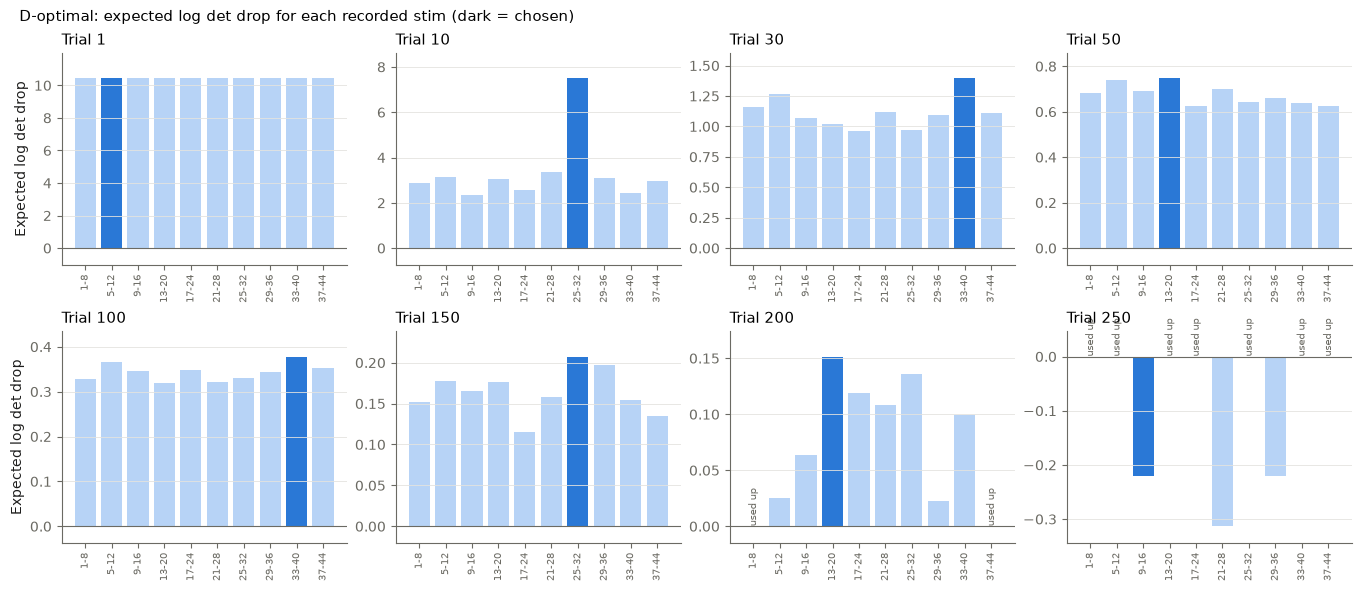

In [115]:
SCORE_RUN = "D-optimal"
SNAPSHOTS = [1, 10, 30, 50, 100, 150, 200, 250]  # trials whose decision to show

h = H[SCORE_RUN]
if "scores" not in h:
    raise KeyError(f"{SCORE_RUN}: history has no scores; rerun it with the current wasabi_online.py")
gain = h["score_prior_logdet"][:, None] - h["scores"]  # (decisions, stims), NaN = used up
snaps = [t for t in SNAPSHOTS if t <= len(gain)]
x = np.arange(len(labels))

cols = 4
rows = -(-len(snaps) // cols)
fig, axes = plt.subplots(rows, cols, figsize=(13.5, 2.9 * rows), constrained_layout=True, squeeze=False)
for ax, t in zip(axes.flat, snaps):
    g = gain[t - 1]
    chosen = h["choice"][t - 1]
    colors = [COLORS[SCORE_RUN] if i == chosen else "#b7d3f6" for i in x]
    ax.bar(x, np.nan_to_num(g), width=0.8, color=colors)
    for i in np.flatnonzero(~np.isfinite(g)):
        ax.text(i, 0, "used up", rotation=90, ha="center", va="bottom", fontsize=7, color=MUTED)
    # A negative drop (expected log det going up) can only come from numerical error, so show it
    lo, hi = min(0.0, np.nanmin(g)), max(0.0, np.nanmax(g))
    ax.axhline(0, color=MUTED, linewidth=0.8)
    ax.set(title=f"Trial {t}", xticks=x, ylim=(lo - 0.1 * (hi - lo), hi + 0.15 * (hi - lo)))
    ax.set_xticklabels(labels, rotation=90, fontsize=7)
    ax.grid(axis="y")
for ax in axes[:, 0]:
    ax.set_ylabel("Expected log det drop")
for ax in axes.flat[len(snaps):]:
    ax.set_visible(False)
fig.suptitle(f"{SCORE_RUN}: expected log det drop for each recorded stim (dark = chosen)",
             x=0.01, ha="left", fontsize=11)
plt.show()

The same over the whole replay: each stim's expected drop at every decision (blank once its
trials are used up), on a linear and a log scale.

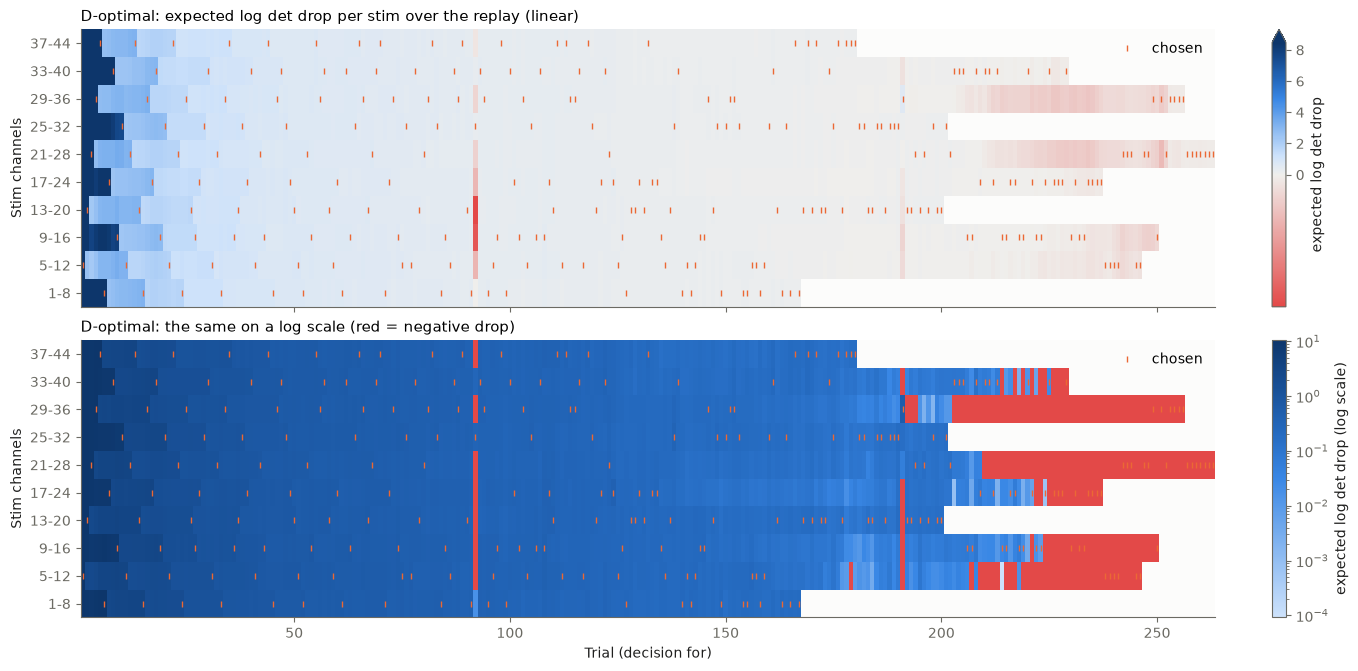

67 decisions have a negative expected drop (red): the B covariance update went the wrong way, a sign of numerical error


In [116]:
fig, axes = plt.subplots(2, 1, figsize=(13.5, 6.6), sharex=True, constrained_layout=True)
extent = (0.5, len(gain) + 0.5, -0.5, len(labels) - 0.5)
pos = ["#f0efec", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]

# Linear scale. Positive drops in blue, negative ones (numerical error, see above) in red,
# neutral at 0; the top of the scale is the 98th percentile so the first few trials, whose
# drops are ~10x the rest, do not wash out the session (colorbar arrow = clipped).
# TwoSlopeNorm puts 0 at the middle of the colormap, so the neutral sits at 0.5
nodes = [(0.0, "#e34948"), (0.5, pos[0])] + [(0.5 + 0.5 * k / (len(pos) - 1), col) for k, col in enumerate(pos[1:], 1)]
div = matplotlib.colors.LinearSegmentedColormap.from_list("div", nodes)
div.set_bad("#fcfcfb")
vmax = np.nanpercentile(gain, 98)
vmin = min(np.nanmin(gain), -1e-6 * vmax)
im = axes[0].imshow(np.ma.masked_invalid(gain.T), aspect="auto", interpolation="nearest", origin="lower", cmap=div,
                    norm=matplotlib.colors.TwoSlopeNorm(vmin=vmin, vcenter=0.0, vmax=vmax), extent=extent)
fig.colorbar(im, ax=axes[0], label="expected log det drop", extend="max")
axes[0].set_title(f"{SCORE_RUN}: expected log det drop per stim over the replay (linear)")

# Log scale: positive drops only; negative ones cannot be shown on it, so they are solid red
seq = matplotlib.colors.LinearSegmentedColormap.from_list("seq_blue", pos[1:])
seq.set_bad("#fcfcfb")
im = axes[1].imshow(np.ma.masked_invalid(np.where(gain > 0, gain, np.nan).T), aspect="auto", interpolation="nearest",
                    origin="lower", cmap=seq, norm=matplotlib.colors.LogNorm(), extent=extent)
negative = np.ma.masked_where(~(gain < 0).T, np.ones_like(gain.T))
axes[1].imshow(negative, aspect="auto", interpolation="nearest", origin="lower", extent=extent,
               cmap=matplotlib.colors.ListedColormap(["#e34948"]))
fig.colorbar(im, ax=axes[1], label="expected log det drop (log scale)")
axes[1].set_title(f"{SCORE_RUN}: the same on a log scale (red = negative drop)")

for ax in axes:
    ax.plot(np.arange(1, len(h["choice"]) + 1), h["choice"], linestyle="none", marker="|", markersize=4,
            color="#eb6834", label="chosen")
    ax.set(yticks=np.arange(len(labels)), yticklabels=labels, ylabel="Stim channels")
    ax.legend(loc="upper right")
axes[1].set_xlabel("Trial (decision for)")
plt.show()
num_neg = int((gain < 0).any(axis=1).sum())
if num_neg:
    print(f"{num_neg} decisions have a negative expected drop (red): the B covariance update "
          "went the wrong way, a sign of numerical error")